import libraries

In [11]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from skopt import BayesSearchCV
from skopt.space import Real, Categorical

from sklearn.feature_selection import RFE, SelectKBest, chi2

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

from scipy.stats import loguniform

load dataset

In [12]:
df = pd.read_csv('FakeNewsNet.csv')

df = df.dropna(subset=['real'])

X = df['title'].fillna('')
y = df['real']

print("Dataset Shape:", df.shape)
print(df.head())
print("\nClass Distribution:")
print(y.value_counts())

Dataset Shape: (23196, 5)
                                               title  \
0  Kandi Burruss Explodes Over Rape Accusation on...   
1  People's Choice Awards 2018: The best red carp...   
2  Sophia Bush Sends Sweet Birthday Message to 'O...   
3  Colombian singer Maluma sparks rumours of inap...   
4  Gossip Girl 10 Years Later: How Upper East Sid...   

                                            news_url        source_domain  \
0  http://toofab.com/2017/05/08/real-housewives-a...           toofab.com   
1  https://www.today.com/style/see-people-s-choic...        www.today.com   
2  https://www.etonline.com/news/220806_sophia_bu...     www.etonline.com   
3  https://www.dailymail.co.uk/news/article-33655...  www.dailymail.co.uk   
4  https://www.zerchoo.com/entertainment/gossip-g...      www.zerchoo.com   

   tweet_num  real  
0         42     1  
1          0     1  
2         63     1  
3         20     1  
4         38     1  

Class Distribution:
real
1    17441
0     5755


train test split

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 18556
Testing Samples: 4640


TASK 1: Grid Search and Random Search

Create SVM Pipeline

In [14]:
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        stop_words='english',
        max_features=5000
    )),
    ('classifier', SVC())
])

Grid Search

In [16]:
param_grid = {
    'classifier__C': [0.1, 1],
    'classifier__kernel': ['linear', 'rbf'],
    'classifier__gamma': ['scale', 'auto']
}

start = time.time()

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

grid_time = time.time() - start

print("Best Parameters:", grid_search.best_params_)
print("Best Accuracy:", grid_search.best_score_)
print("Execution Time:", round(grid_time, 2), "seconds")

Best Parameters: {'classifier__C': 1, 'classifier__gamma': 'scale', 'classifier__kernel': 'linear'}
Best Accuracy: 0.8370877538078307
Execution Time: 173.61 seconds


Random Search

In [18]:
param_dist = {
    'classifier__C': loguniform(0.1, 100),
    'classifier__kernel': ['linear', 'rbf'],
    'classifier__gamma': ['scale', 'auto']
}

start = time.time()

random_search = RandomizedSearchCV(
    pipeline,
    param_distributions=param_dist,
    n_iter=10,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

random_time = time.time() - start

print("Best Parameters:", random_search.best_params_)
print("Best Accuracy:", random_search.best_score_)
print("Execution Time:", round(random_time, 2), "seconds")

Best Parameters: {'classifier__C': np.float64(0.8179499475211672), 'classifier__gamma': 'auto', 'classifier__kernel': 'linear'}
Best Accuracy: 0.8366027093454217
Execution Time: 160.05 seconds


Compare Grid and Random Search

In [19]:
task1_results = pd.DataFrame({
    'Technique': ['Grid Search', 'Random Search'],
    'Best CV Accuracy': [
        grid_search.best_score_,
        random_search.best_score_
    ],
    'Execution Time': [
        grid_time,
        random_time
    ]
})

print(task1_results.round(4))

       Technique  Best CV Accuracy  Execution Time
0    Grid Search            0.8371        173.6132
1  Random Search            0.8366        160.0515


TASK 2: Bayesian Optimization

Apply Bayesian Optimization

In [20]:
search_space = {
    'classifier__C': Real(0.1, 10, prior='log-uniform'),
    'classifier__kernel': Categorical(['linear', 'rbf']),
    'classifier__gamma': Categorical(['scale', 'auto'])
}

start = time.time()

bayes_search = BayesSearchCV(
    pipeline,
    search_spaces=search_space,
    n_iter=5,
    cv=2,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

bayes_search.fit(X_train, y_train)

bayes_time = time.time() - start

print("Best Parameters:", bayes_search.best_params_)
print("Best Accuracy:", bayes_search.best_score_)
print("Execution Time:", round(bayes_time, 2), "seconds")

Fitting 2 folds for each of 1 candidates, totalling 2 fits
Fitting 2 folds for each of 1 candidates, totalling 2 fits
Fitting 2 folds for each of 1 candidates, totalling 2 fits
Fitting 2 folds for each of 1 candidates, totalling 2 fits
Fitting 2 folds for each of 1 candidates, totalling 2 fits
Best Parameters: OrderedDict({'classifier__C': 3.9728931339630273, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'})
Best Accuracy: 0.8326147876697564
Execution Time: 211.53 seconds


Compare All Three Optimization Techniques

In [21]:
task2_results = pd.DataFrame({
    'Technique': [
        'Grid Search',
        'Random Search',
        'Bayesian Optimization'
    ],
    'Best CV Accuracy': [
        grid_search.best_score_,
        random_search.best_score_,
        bayes_search.best_score_
    ],
    'Execution Time': [
        grid_time,
        random_time,
        bayes_time
    ]
})

print(task2_results.round(4))

               Technique  Best CV Accuracy  Execution Time
0            Grid Search            0.8371        173.6132
1          Random Search            0.8366        160.0515
2  Bayesian Optimization            0.8326        211.5299


Evaluate Optimized Models

In [22]:
models = {
    'Grid Search': grid_search.best_estimator_,
    'Random Search': random_search.best_estimator_,
    'Bayesian Optimization': bayes_search.best_estimator_
}

evaluation = []

for name, model in models.items():

    pred = model.predict(X_test)

    evaluation.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1 Score': f1_score(y_test, pred, zero_division=0)
    })

task2_evaluation = pd.DataFrame(evaluation)

print(task2_evaluation.round(4))

                   Model  Accuracy  Precision  Recall  F1 Score
0            Grid Search    0.8494     0.8644  0.9484    0.9045
1          Random Search    0.8489     0.8615  0.9521    0.9046
2  Bayesian Optimization    0.8461     0.8713  0.9332    0.9012


Visualize Optimization Results

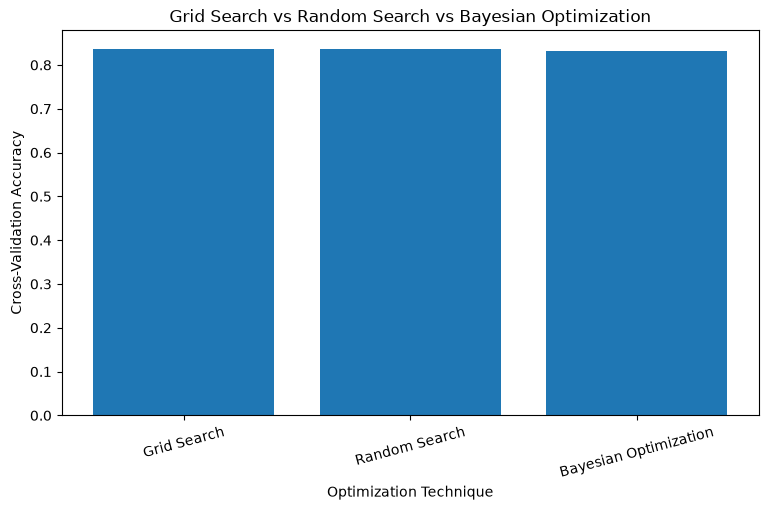

In [23]:
plt.figure(figsize=(9, 5))

plt.bar(
    task2_results['Technique'],
    task2_results['Best CV Accuracy']
)

plt.xlabel('Optimization Technique')
plt.ylabel('Cross-Validation Accuracy')
plt.title('Grid Search vs Random Search vs Bayesian Optimization')

plt.xticks(rotation=15)
plt.show()

TASK 3: Comparative Study of Feature Selection Techniques

Apply TF-IDF

In [24]:
tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=3000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Original Features:", X_train_tfidf.shape[1])
feature_results = []

Original Features: 3000


Baseline Mode

In [25]:
baseline = LogisticRegression(max_iter=2000)

baseline.fit(X_train_tfidf, y_train)

baseline_pred = baseline.predict(X_test_tfidf)

feature_results.append({
    'Technique': 'Baseline',
    'Features': X_train_tfidf.shape[1],
    'Accuracy': accuracy_score(y_test, baseline_pred),
    'Precision': precision_score(y_test, baseline_pred, zero_division=0),
    'Recall': recall_score(y_test, baseline_pred, zero_division=0),
    'F1 Score': f1_score(y_test, baseline_pred, zero_division=0)
})

RFE Feature Selection

In [26]:
rfe = RFE(
    estimator=LogisticRegression(max_iter=2000),
    n_features_to_select=500,
    step=0.2
)

X_train_rfe = rfe.fit_transform(X_train_tfidf, y_train)
X_test_rfe = rfe.transform(X_test_tfidf)

model_rfe = LogisticRegression(max_iter=2000)

model_rfe.fit(X_train_rfe, y_train)

rfe_pred = model_rfe.predict(X_test_rfe)

feature_results.append({
    'Technique': 'RFE',
    'Features': X_train_rfe.shape[1],
    'Accuracy': accuracy_score(y_test, rfe_pred),
    'Precision': precision_score(y_test, rfe_pred, zero_division=0),
    'Recall': recall_score(y_test, rfe_pred, zero_division=0),
    'F1 Score': f1_score(y_test, rfe_pred, zero_division=0)
})

LASSO Feature Selection

In [27]:
lasso = LogisticRegression(
    solver='liblinear',
    l1_ratio=1,
    C=1,
    max_iter=2000
)

lasso.fit(X_train_tfidf, y_train)

selected = lasso.coef_[0] != 0

X_train_lasso = X_train_tfidf[:, selected]
X_test_lasso = X_test_tfidf[:, selected]

model_lasso = LogisticRegression(max_iter=2000)

model_lasso.fit(X_train_lasso, y_train)

lasso_pred = model_lasso.predict(X_test_lasso)

feature_results.append({
    'Technique': 'LASSO',
    'Features': selected.sum(),
    'Accuracy': accuracy_score(y_test, lasso_pred),
    'Precision': precision_score(y_test, lasso_pred, zero_division=0),
    'Recall': recall_score(y_test, lasso_pred, zero_division=0),
    'F1 Score': f1_score(y_test, lasso_pred, zero_division=0)
})

SelectKBest Feature Selection

In [28]:
selector = SelectKBest(
    score_func=chi2,
    k=500
)

X_train_kbest = selector.fit_transform(X_train_tfidf, y_train)
X_test_kbest = selector.transform(X_test_tfidf)

model_kbest = LogisticRegression(max_iter=2000)

model_kbest.fit(X_train_kbest, y_train)

kbest_pred = model_kbest.predict(X_test_kbest)

feature_results.append({
    'Technique': 'SelectKBest',
    'Features': X_train_kbest.shape[1],
    'Accuracy': accuracy_score(y_test, kbest_pred),
    'Precision': precision_score(y_test, kbest_pred, zero_division=0),
    'Recall': recall_score(y_test, kbest_pred, zero_division=0),
    'F1 Score': f1_score(y_test, kbest_pred, zero_division=0)
})

Compare Feature Selection Techniques

In [29]:
feature_results_df = pd.DataFrame(feature_results)

print(feature_results_df.round(4))

     Technique  Features  Accuracy  Precision  Recall  F1 Score
0     Baseline      3000    0.8435     0.8514  0.9593    0.9022
1          RFE       500    0.8375     0.8437  0.9622    0.8990
2        LASSO       918    0.8381     0.8459  0.9596    0.8992
3  SelectKBest       500    0.8401     0.8450  0.9642    0.9007


Identify Best Feature Selection Technique

In [30]:
best_feature = feature_results_df.loc[
    feature_results_df['F1 Score'].idxmax()
]

print("Best Feature Selection Technique:")
print(best_feature)

Best Feature Selection Technique:
Technique    Baseline
Features         3000
Accuracy     0.843534
Precision    0.851437
Recall       0.959301
F1 Score     0.902156
Name: 0, dtype: object


Accuracy Comparison Graph

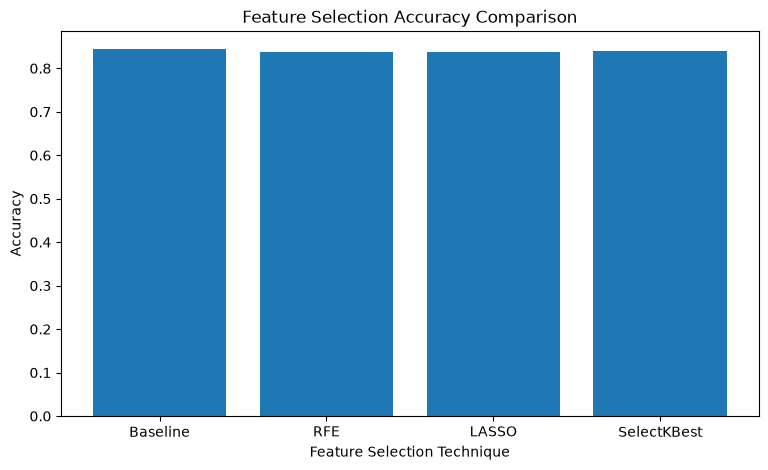

In [31]:
plt.figure(figsize=(9, 5))

plt.bar(
    feature_results_df['Technique'],
    feature_results_df['Accuracy']
)

plt.xlabel('Feature Selection Technique')
plt.ylabel('Accuracy')
plt.title('Feature Selection Accuracy Comparison')

plt.show()

Feature Reduction Graph

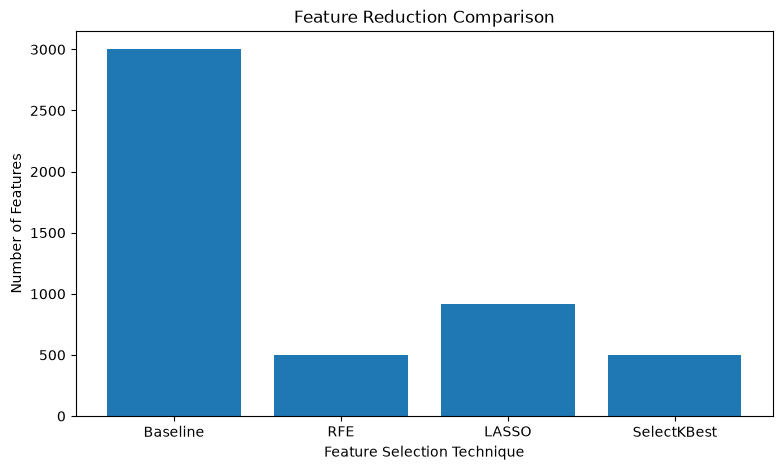

In [32]:
plt.figure(figsize=(9, 5))

plt.bar(
    feature_results_df['Technique'],
    feature_results_df['Features']
)

plt.xlabel('Feature Selection Technique')
plt.ylabel('Number of Features')
plt.title('Feature Reduction Comparison')

plt.show()